# 5. The model: a pretrained U-Net, and a radar student

This notebook opens up the two models: what goes in, what comes out, how they were trained,
and which choices mattered. Nothing here is retrained (that's `make train`, about an hour on
one consumer GPU). We read the saved training logs and run the saved weights.

In [1]:
from hlw.nb import BLUE, GREEN, GREY, ORANGE, setup

setup()
import json

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch

from hlw import aoi
from hlw import config as C
from hlw.blogfigs import rgb
from hlw.dataset import s1_path, s2_path, s2_scl_path
from hlw.evaluate import load_models
from hlw.io import read_raster
from hlw.model import WaterNet, predict_tiled, s1_to_input, s2_to_input

device = "cuda" if torch.cuda.is_available() else "cpu"
print("device:", device, torch.cuda.get_device_name(0) if device == "cuda" else "")

device: cuda NVIDIA GeForce RTX 4070 SUPER


## Architecture: U-Net with a pretrained encoder

A [U-Net](https://arxiv.org/abs/1505.04597) has two halves. An **encoder** shrinks the image
step by step into abstract features ("this patch looks like open water next to a limestone
bank"). A **decoder** grows those features back to full resolution and outputs one number per
pixel, here the probability of water. Skip connections carry fine detail from encoder to
decoder so edges stay sharp.

The encoder is a ResNet-18 whose weights come from **TorchGeo's `SENTINEL2_ALL_MOCO`**. These
weights were learned by self-supervised contrastive learning (MoCo) on SSL4EO-S12, about
250,000 Sentinel-2 locations worldwide, without any labels. The idea is that the encoder
already knows what Sentinel-2 imagery looks like, so our small, noisy label set only has to
teach it the last step.

In [2]:
m = WaterNet("s2", init="none")
n_enc = sum(p.numel() for p in m.net.encoder.parameters())
n_all = sum(p.numel() for p in m.parameters())
print(f"S2 model: {n_all / 1e6:.1f} M parameters, of which encoder {n_enc / 1e6:.1f} M")
print("first conv layer:", m.net.encoder.conv1)

S2 model: 14.4 M parameters, of which encoder 11.2 M
first conv layer: Conv2d(13, 64, kernel_size=(7, 7), stride=(2, 2), padding=(3, 3), bias=False)


The first layer takes **13 channels**, the 13 bands of Sentinel-2 Level-1C that the pretrained
weights expect. We use Level-2A (surface reflectance), which has 12 bands, because band B10
(cirrus, 1.38 µm) is dropped during atmospheric correction. So we insert an all-zero channel
where B10 would be (`s2_to_input`).

That is a small **domain mismatch**: the encoder was pretrained on top-of-atmosphere L1C
values, and we feed it surface reflectance. Fine-tuning absorbs most of it, but it is one
reason pretraining might help less here than in the papers.

## Training data: weak labels, sampled where it matters

Training draws random 256 × 256 pixel windows (2.56 km) from 208 clear training scenes. Two
details matter more than they look:

* **Shoreline-biased sampling.** Window centres in the JRC fluctuation band are drawn 4× as
  often as elsewhere. Most of a lake zone is easy (deep water or dry land), and a model trained
  on uniform windows spends its effort there.
* **Masked loss.** Pixels labelled 255 (cloud, outside the zone, SCL water outside JRC history)
  are left out of the loss entirely. "Don't know" is not the same as "land", and training
  on it as land would teach the model that shadowy water is land.

Training: 2,000 steps of batch 16, AdamW, one-cycle learning rate, the pretrained encoder at a
third of the decoder's learning rate (so the pretrained features are nudged, not overwritten).
Random rotations, flips and ±10 % brightness jitter.

,run,minutes,gpu
0,s1_holdout_buchanan_teacher_moco_s0,3.58,NVIDIA GeForce RTX 4070 SUPER
1,s1_holdout_travis_teacher_moco_s0,2.79,NVIDIA GeForce RTX 4070 SUPER
2,s2_holdout_buchanan_scl_jrc_moco_s0,5.70,NVIDIA GeForce RTX 4070 SUPER
3,s2_holdout_buchanan_scl_jrc_moco_s1,5.74,NVIDIA GeForce RTX 4070 SUPER
4,s2_holdout_buchanan_scl_jrc_moco_s2,5.79,NVIDIA GeForce RTX 4070 SUPER
5,s2_holdout_travis_jrc50_moco_s0,5.88,NVIDIA GeForce RTX 4070 SUPER
6,s2_holdout_travis_scl_jrc_moco_s0,7.86,NVIDIA GeForce RTX 4070 SUPER
7,s2_holdout_travis_scl_jrc_moco_s1,5.90,NVIDIA GeForce RTX 4070 SUPER
8,s2_holdout_travis_scl_jrc_moco_s2,6.61,NVIDIA GeForce RTX 4070 SUPER
9,s2_holdout_travis_scl_jrc_none_s0,12.51,NVIDIA GeForce RTX 4070 SUPER


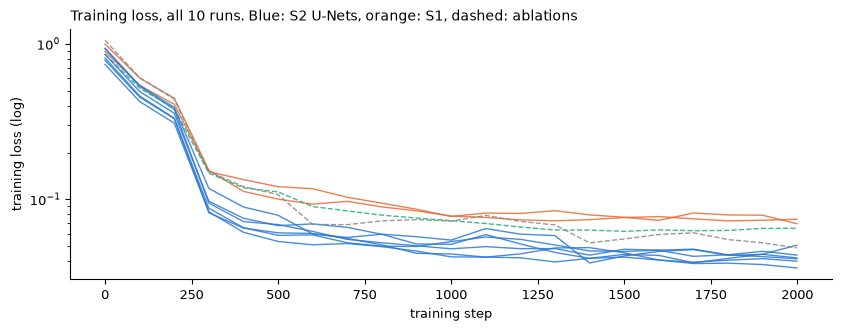

In [3]:
runs = sorted(C.RUNS_DIR.glob("*/meta.json"))
fig, ax = plt.subplots(figsize=(8.5, 3.4))
rows = []
for r in runs:
    meta = json.loads(r.read_text())
    log = pd.DataFrame(meta["log"])
    style = {"s1": (ORANGE, "-"), "none": (GREY, "--"), "jrc50": (GREEN, "--")}
    key = "s1" if meta["sensor"] == "s1" else meta["init"] if meta["init"] == "none" \
        else meta["label"] if meta["label"] == "jrc50" else "s2"
    c, ls = style.get(key, (BLUE, "-"))
    ax.plot(log["iter"], log["loss"].rolling(3, min_periods=1).mean(), color=c, ls=ls, lw=1,
            alpha=0.85)
    rows.append({"run": meta["name"], "minutes": meta["train_minutes"], "gpu": meta["gpu"]})
ax.set(yscale="log", xlabel="training step", ylabel="training loss (log)",
       title="Training loss, all 10 runs. Blue: S2 U-Nets, orange: S1, dashed: ablations")
plt.tight_layout()
pd.DataFrame(rows)

Each S2 run took 6-8 minutes on an RTX 4070 SUPER (the random-init run 12.5 min), and each S1
run about 3 minutes. That fits the brief's "laptop or free GPU notebook" budget.

Don't compare loss values *across* kinds of run; each line measures fit to a different target.

* The **S1** runs (orange) learn soft probabilities from the teacher. Cross-entropy against a
  soft target can't reach zero, so their floor is higher by construction.
* The **JRC-label** run (green dashed) can't fit its labels well, because a static map
  contradicts the image wherever the lake has moved since. Its higher loss is a symptom of
  label noise, not of a weaker network.
* The **random-init** run (grey dashed) starts slower and is still improving at step 2,000.

Training loss tells you whether optimisation worked. It says nothing about accuracy against
the real world; only the independent test points can.

## What the model outputs

Let's run the three-seed ensemble for the fold that never saw Lake Travis, on a Travis scene
from February 2022, and look at a window around the main channel.

pixels with 0.05 < p < 0.95: 3.18% of the zone


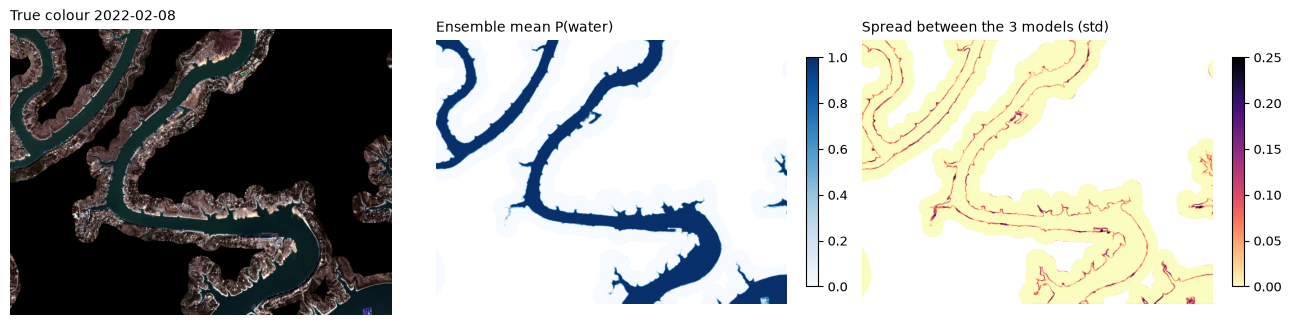

In [4]:
LAKE, D2, D1 = "travis", "2022-02-08", "2022-02-09"
refl = read_raster(s2_path(LAKE, D2))[0]
zone, _, _ = aoi.load_zone(LAKE)
y0, x0, H, W = 1500, 1900, 768, 1024
sl = (slice(y0, y0 + H), slice(x0, x0 + W))
s2_models = load_models("s2", "holdout_travis")
p, std = predict_tiled(s2_models, s2_to_input(refl[:, sl[0], sl[1]]), device=device)
inz = zone[sl] & (refl[2][sl] > 0)

fig, axes = plt.subplots(1, 3, figsize=(13, 3.6))
axes[0].imshow(rgb(refl, zone & (refl[2] > 0), sl))
axes[0].set_title(f"True colour {D2}")
im1 = axes[1].imshow(np.where(inz, p, np.nan), cmap="Blues", vmin=0, vmax=1)
axes[1].set_title("Ensemble mean P(water)")
im2 = axes[2].imshow(np.where(inz, std, np.nan), cmap="magma_r", vmin=0, vmax=0.25)
axes[2].set_title("Spread between the 3 models (std)")
for ax in axes:
    ax.set_axis_off()
fig.colorbar(im1, ax=axes[1], fraction=0.03)
fig.colorbar(im2, ax=axes[2], fraction=0.03)
plt.tight_layout()
print(f"pixels with 0.05 < p < 0.95: {((p > 0.05) & (p < 0.95) & inz).mean():.2%} of the zone")

The probabilities are almost all near 0 or 1, with a thin band of intermediate values along
the shore. The spread between the three models (trained identically except for the random
seed) is concentrated in exactly that band. This is the **ensemble** form of uncertainty: where
independently trained models disagree, don't trust any of them much. Notebook 6 checks
whether that signal really points at errors.

## The radar student

Radar has no SCL-like water label to learn from, and hand-labelling radar is hard even for
people. So the S1 model learns from the **S2 model** instead: *knowledge distillation*.

1. Find Sentinel-1 passes within ±2 days of a clear Sentinel-2 pass, when the official lake
   level moved less than 0.15 ft. The shoreline is then the same in both images.
2. Run the S2 ensemble on the optical image. Its probabilities become the radar model's
   training target (the "teacher").
3. Train an S1 U-Net (ResNet-50 encoder, TorchGeo `SENTINEL1_ALL_MOCO`) to reproduce those
   probabilities from the VV/VH backscatter alone.

Once trained, the student needs no optical image at all, so it works through cloud. This pair
is a held-out example: the radar model below never saw Travis.

agreement with the optical map: S1 U-Net 96.3%, VV threshold 90.8%


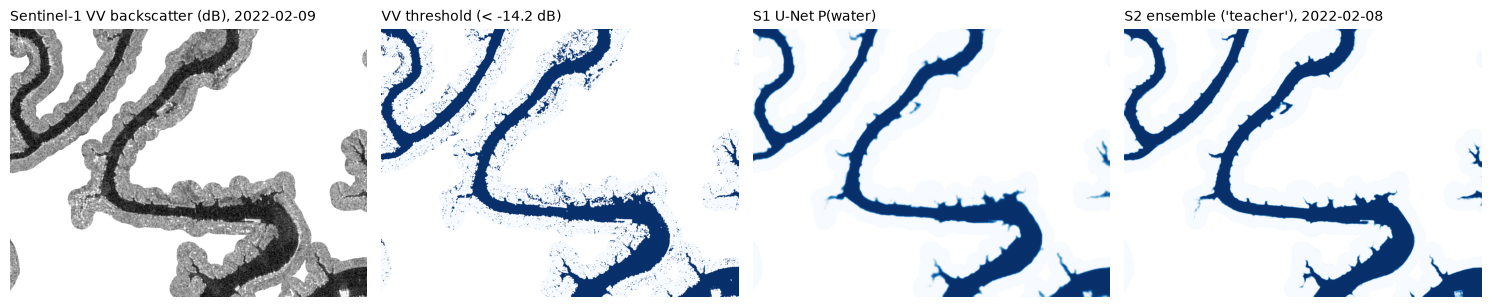

In [5]:
db = read_raster(s1_path(LAKE, D1))[0].astype(np.float32) / 100
db[db <= -300] = np.nan
s1_model = load_models("s1", "holdout_travis", seeds=(0,))
ps1, _ = predict_tiled(s1_model, s1_to_input(db[:, sl[0], sl[1]]), device=device)
cuts = json.loads((C.RESULTS_DIR / "cutoffs.json").read_text())
vv_cut = cuts[f"vv:{LAKE}"]["cutoff"]
vv = db[0][sl]

fig, axes = plt.subplots(1, 4, figsize=(15, 3.4))
axes[0].imshow(np.where(inz, vv, np.nan), cmap="gray", vmin=-25, vmax=0)
axes[0].set_title(f"Sentinel-1 VV backscatter (dB), {D1}")
axes[1].imshow(np.where(inz, vv < vv_cut, np.nan), cmap="Blues", vmin=0, vmax=1)
axes[1].set_title(f"VV threshold (< {vv_cut:.1f} dB)")
axes[2].imshow(np.where(inz, ps1, np.nan), cmap="Blues", vmin=0, vmax=1)
axes[2].set_title("S1 U-Net P(water)")
axes[3].imshow(np.where(inz, p, np.nan), cmap="Blues", vmin=0, vmax=1)
axes[3].set_title(f"S2 ensemble ('teacher'), {D2}")
for ax in axes:
    ax.set_axis_off()
plt.tight_layout()
agree = ((ps1 > 0.5) == (p > 0.5))[inz].mean()
agree_vv = ((vv < vv_cut) == (p > 0.5))[inz & np.isfinite(vv)].mean()
print(f"agreement with the optical map: S1 U-Net {agree:.1%}, VV threshold {agree_vv:.1%}")

The raw VV image is speckled, and the threshold map inherits the speckle: isolated "water"
pixels on land and holes in the lake wherever wind roughens the surface. The radar U-Net uses
**context** (shape, texture, neighbouring pixels) to produce a clean, lake-shaped map. Spatial
context is what a convolutional network adds over a per-pixel threshold, and with speckled
radar the gap is large.

## Which choices mattered? (ablations)

Two single-seed ablations, both in the Travis-held-out fold, scored on the same held-out points:

In [6]:
pdiff = pd.read_csv(C.RESULTS_DIR / "paired_differences.csv")
pdiff[(pdiff.group == "all_heldout") & pdiff.question.str.contains("pretraining|labels")][
    ["question", "d_iou", "d_iou_lo", "d_iou_hi", "n"]].round(3)

,question,d_iou,d_iou_lo,d_iou_hi,n
5,MoCo pretraining vs random init (Travis fold),0.003,-0.012,0.018,318
6,per-scene SCL labels vs static JRC labels (Tra...,0.175,0.110,0.241,318


* **Pretraining** (MoCo weights vs random initialisation): +0.003 IoU, with an interval
  comfortably spanning zero. With 208 training scenes and an easy target, starting from scratch gets
  nearly as far, so the pretrained encoder isn't what makes this model work.
* **Label choice** (per-scene SCL ∩ JRC vs static JRC): **+0.175 IoU**, far larger and far
  outside noise. What the model learns from matters far more than where its weights start.

## Takeaways

* A pretrained U-Net is small, cheap to fine-tune (minutes) and easy to run on new imagery.
* Most of its quality here comes from **the labels and the sampling**, not the pretraining.
* Distillation lets a radar model inherit an optical model's skill without a single radar
  label, and spatial context fixes the speckle that defeats radar thresholds.

Next: [6 · evaluation and uncertainty](06_evaluation_and_uncertainty.ipynb)